# ALR / ILR vs CLR / Euclidean comparison

| Method | Transform | Space | Dimension |
|--------|-----------|-------|-----------|
| **Euclidean** | none | simplex | n (rank-deficient) |
| **Aitchison (CLR)** | CLR: log xᵢ − mean(log x) | ℝⁿ (rank n-1) | n |
| **ALR** | log(xᵢ/xₙ), i=1…n-1 | ℝⁿ⁻¹ | n-1 |
| **ILR** | Ψ · CLR(x), Gram-Schmidt | ℝⁿ⁻¹ (isometric) | n-1 |
| **Leave-One-Out** | drop last + scale | ℝⁿ⁻¹ | n-1 |

In [10]:
import jax
import jax.numpy as jnp
import numpy as np
import pandas as pd
import optimistix
import matplotlib.pyplot as plt
import seaborn as sns

from jax import config as jax_config
jax_config.update("jax_enable_x64", True)

from tca_openflux import (
    TCA_OpenFLux, objective_wssr, objective_clr_wssr,
    objective_alr_wssr, objective_ilr_wssr,
    objective_leave_one_out_wssr,
)
from emu_example import closure, clr_func, ilr_func
from helper.coda import alr_func

METHODS = ["Euclidean", "CLR", "ALR", "ILR", "LeaveOneOut"]
MARKERS = {"Euclidean": "o", "CLR": "s", "ALR": "D", "ILR": "v", "LeaveOneOut": "^"}
PALETTE = sns.color_palette("colorblind", n_colors=5)

In [11]:
def fva_full(parameters: dict[str, float]) -> dict:
    """Run all 5 flux-estimation methods and return estimated fluxes."""

    fixed = {"v1": 1.0, "v16": 0.07, "v17": 0.23, "v18": 0.12, "v19": 0.05, "v20": 0.03}

    # ── True MIDs ─────────────────────────────────────────────────────────────
    true_data = TCA_OpenFLux(parameters=parameters, fixed=fixed)

    # ── Simulate noisy observations (1000 draws, CV=10%) ─────────────────────
    key = jax.random.PRNGKey(1234)
    sims = 1000
    total_isos = jax.tree.map(lambda x: x * 1e5, true_data)
    norm_sigma = jax.tree.map(lambda x: x * 0.1, total_isos)
    _, key_sim = jax.random.split(key)
    norm_sim   = jax.tree.map(
        lambda m, s: m + s * jax.random.normal(key_sim, (sims, m.shape[0])),
        total_isos, norm_sigma,
    )
    iso_prop = jax.tree.map(closure, norm_sim)

    # ── Euclidean ─────────────────────────────────────────────────────────────
    mean_sim = jax.tree.map(lambda x: jnp.mean(x, axis=0), iso_prop)
    std_sim  = jax.tree.map(lambda x: jnp.std( x, axis=0), iso_prop)
    D_sim    = jax.tree.map(jnp.diag, std_sim)

    # ── CLR (Aitchison) ───────────────────────────────────────────────────────
    iso_clr  = jax.tree.map(lambda m: jax.vmap(clr_func)(m), iso_prop)
    mean_clr = jax.tree.map(lambda x: jnp.mean(x, axis=0), iso_clr)
    std_clr  = jax.tree.map(lambda x: jnp.std( x, axis=0), iso_clr)
    D_clr    = jax.tree.map(jnp.diag, std_clr)

    # ── ALR ───────────────────────────────────────────────────────────────────
    iso_alr  = jax.tree.map(lambda m: jax.vmap(alr_func)(m), iso_prop)
    mean_alr = jax.tree.map(lambda x: jnp.mean(x, axis=0), iso_alr)
    std_alr  = jax.tree.map(lambda x: jnp.std( x, axis=0), iso_alr)
    D_alr    = jax.tree.map(jnp.diag, std_alr)

    # ── ILR ───────────────────────────────────────────────────────────────────
    iso_ilr  = jax.tree.map(lambda m: jax.vmap(ilr_func)(m), iso_prop)
    mean_ilr = jax.tree.map(lambda x: jnp.mean(x, axis=0), iso_ilr)
    std_ilr  = jax.tree.map(lambda x: jnp.std( x, axis=0), iso_ilr)
    D_ilr    = jax.tree.map(jnp.diag, std_ilr)

    # ── Solver ────────────────────────────────────────────────────────────────
    solver      = optimistix.BFGS(rtol=1e-12, atol=1e-12, verbose=frozenset())
    init_params = {"v8": 0.2, "v2": 0.2, "v9": 0.3}

    result_euc = optimistix.minimise(
        objective_wssr, y0=init_params,
        args=(mean_sim, D_sim, fixed), solver=solver, max_steps=10000,
    )
    result_ait = optimistix.minimise(
        objective_clr_wssr, y0=init_params,
        args=(mean_clr, D_clr, fixed), solver=solver, max_steps=10000,
    )
    result_alr = optimistix.minimise(
        objective_alr_wssr, y0=init_params,
        args=(mean_alr, D_alr, fixed), solver=solver, max_steps=10000,
    )
    result_ilr = optimistix.minimise(
        objective_ilr_wssr, y0=init_params,
        args=(mean_ilr, D_ilr, fixed), solver=solver, max_steps=10000,
    )

    init_params_loo = {
        "fluxes": {"v8": 0.2, "v2": 0.2, "v9": 0.3},
        "scales": jax.tree.map(lambda _: 1.0, mean_sim),
    }
    result_loo = optimistix.minimise(
        objective_leave_one_out_wssr, y0=init_params_loo,
        args=(mean_sim, D_sim, fixed), solver=solver, max_steps=10000,
    )

    true_mids = {k: np.array(v) for k, v in true_data.items()}

    return {
        "Euclidean":   result_euc.value,
        "CLR":   result_ait.value,
        "ALR":         result_alr.value,
        "ILR":         result_ilr.value,
        "LeaveOneOut": result_loo.value["fluxes"],
        "true_mids":   true_mids,
    }

## Quick 3-sample sanity check

In [12]:
flux_vars = ["v2", "v8", "v9"]

test_params = [
    {"v8": 0.200, "v2": 0.190, "v9": 0.190},
    {"v8": 0.210, "v2": 0.200, "v9": 0.200},
    {"v8": 0.220, "v2": 0.210, "v9": 0.210},
]

results_test = [fva_full(p) for p in test_params]

for i, (true, res) in enumerate(zip(test_params, results_test)):
    print(f"\nSample {i}: true = {true}")
    for m in METHODS:
        est = {k: float(res[m][k]) for k in flux_vars}
        print(f"  {m:12s}: {est}")


Sample 0: true = {'v8': 0.2, 'v2': 0.19, 'v9': 0.19}
  Euclidean   : {'v2': 0.1905856760096785, 'v8': 0.20133919287870386, 'v9': 0.1924961417916779}
  CLR         : {'v2': 0.19002687124488482, 'v8': 0.19914031978349303, 'v9': 0.18954680766550908}
  ALR         : {'v2': 0.18999147031889624, 'v8': 0.20096241658564798, 'v9': 0.18899404488159693}
  ILR         : {'v2': 0.1900345356673345, 'v8': 0.19915896216639611, 'v9': 0.18956013423456253}
  LeaveOneOut : {'v2': 0.19066294736694747, 'v8': 0.20095931044169868, 'v9': 0.1927259608014312}

Sample 1: true = {'v8': 0.21, 'v2': 0.2, 'v9': 0.2}
  Euclidean   : {'v2': 0.20058890426309597, 'v8': 0.2113873843375881, 'v9': 0.20250634956827546}
  CLR         : {'v2': 0.20002871402908085, 'v8': 0.20910591271048448, 'v9': 0.19955430580818032}
  ALR         : {'v2': 0.19998659428049578, 'v8': 0.21101755749983306, 'v9': 0.1989552232898877}
  ILR         : {'v2': 0.20003657699454683, 'v8': 0.20912536499997897, 'v9': 0.19956782708792012}
  LeaveOneOut : {

## Batch run — LHS samples from flux_range.ipynb

In [13]:
flux_df = pd.read_csv("flux_sampling/flux_samples_R2_R8_R9_validated.csv", index_col="Sample")
print(f"Loaded {len(flux_df)} LHS samples:")
print(flux_df.round(4))

batch_true = []
batch_results = {m: [] for m in METHODS}
batch_true_mids = []

for sample_id, row in flux_df.iterrows():
    params = {"v2": float(row["R2"]), "v8": float(row["R8"]), "v9": float(row["R9"])}
    result = fva_full(params)
    batch_true.append(params)
    for m in METHODS:
        batch_results[m].append(result[m])
    batch_true_mids.append(result["true_mids"])

print(f"\nFinished {len(batch_true)} runs.")

Loaded 50 LHS samples:
            R2      R8      R9
Sample                        
0      0.11320 0.59500 0.32460
1      0.06800 0.75130 0.37590
2      0.03450 0.31940 0.11790
3      0.03040 0.44350 0.21190
4      0.14900 0.74920 0.14410
5      0.14940 0.70470 0.28010
6      0.03830 0.56600 0.34290
7      0.09380 0.27240 0.39700
8      0.10550 0.85880 0.06950
9      0.08300 0.31250 0.10200
10     0.13520 0.60000 0.17020
11     0.09170 0.11650 0.15910
12     0.08330 0.01280 0.35270
13     0.09570 0.16290 0.06320
14     0.06880 0.05400 0.11570
15     0.02370 0.38410 0.40780
16     0.03830 0.87620 0.40410
17     0.03520 0.52230 0.22890
18     0.01770 0.06190 0.26970
19     0.20380 0.50610 0.32560
20     0.24110 0.52230 0.36070
21     0.20960 0.30280 0.40230
22     0.03280 0.21420 0.41580
23     0.03580 0.83920 0.00870
24     0.18140 0.23030 0.33370
25     0.17280 0.82830 0.32320
26     0.18250 0.28880 0.28830
27     0.03340 0.57960 0.13760
28     0.14870 0.22070 0.41110
29     0.05850 0

## Build tidy DataFrame + IQR outlier detection

In [14]:
true_arr = {v: np.array([d[v] for d in batch_true]) for v in flux_vars}

records = []
for i in range(len(batch_true)):
    for v in flux_vars:
        for method in METHODS:
            records.append({
                "Sample":    i,
                "Flux":      v,
                "Method":    method,
                "True":      true_arr[v][i],
                "Estimated": float(batch_results[method][i][v]),
                "Residual":  float(batch_results[method][i][v]) - true_arr[v][i],
            })

df = pd.DataFrame(records)

# IQR outlier detection
abs_res = df.groupby("Sample")["Residual"].apply(lambda x: np.abs(x).max())
q1, q3  = abs_res.quantile(0.25), abs_res.quantile(0.75)
iqr     = q3 - q1
outlier_samples = set(abs_res[abs_res > q3 + 1.5 * iqr].index.tolist())

df["Outlier"] = df["Sample"].isin(outlier_samples)
df_clean = df[~df["Outlier"]]
n_out = len(outlier_samples)
print(f"Outliers: {sorted(outlier_samples)}  ({n_out}/{len(batch_true)} removed)")

Outliers: [2, 6, 17, 22, 23, 27, 35, 37, 45]  (9/50 removed)


## Residual plots (5 methods)

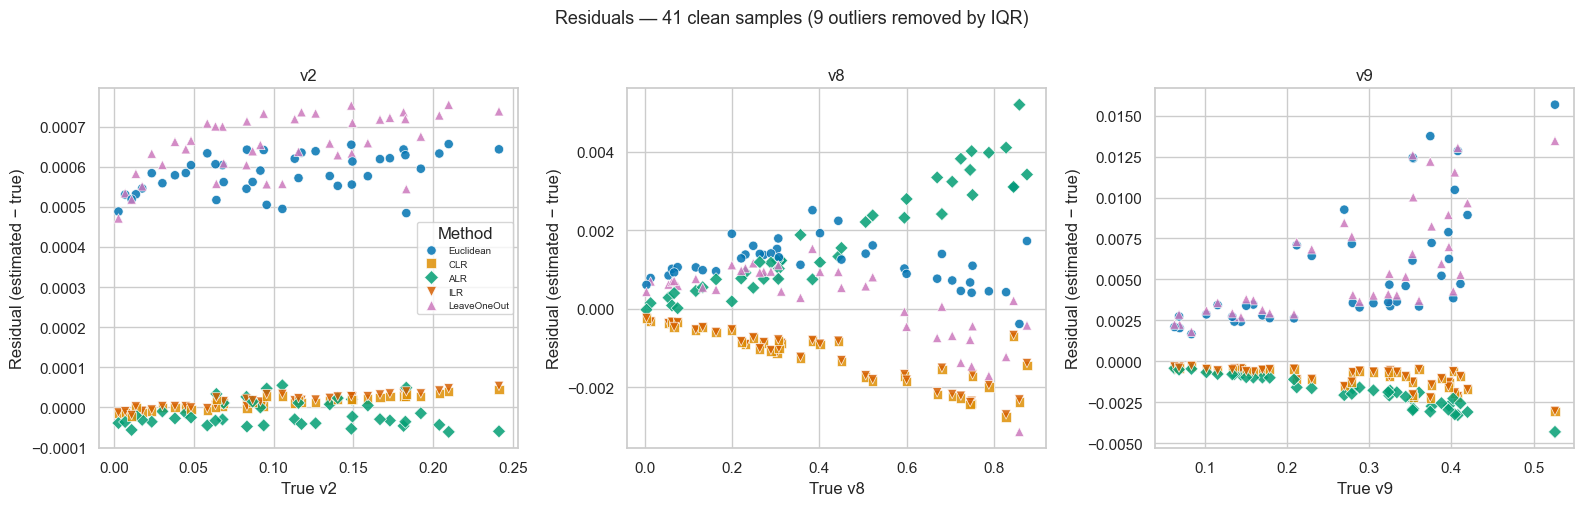

In [15]:
sns.set_theme(style="whitegrid", palette="colorblind")
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(
    f"Residuals — {len(batch_true) - n_out} clean samples "
    f"({n_out} outlier{'s' if n_out != 1 else ''} removed by IQR)",
    fontsize=13, y=1.01,
)

for col, v in enumerate(flux_vars):
    sub = df_clean[df_clean["Flux"] == v]
    ax = axes[col]
    sns.scatterplot(
        data=sub, x="True", y="Residual",
        hue="Method", style="Method", markers=MARKERS,
        hue_order=METHODS, style_order=METHODS,
        palette="colorblind", s=45, alpha=0.85,
        ax=ax, legend=(col == 0),
    )
    ax.set_title(v)
    ax.set_xlabel(f"True {v}")
    ax.set_ylabel("Residual (estimated \u2212 true)")
    if col == 0:
        ax.legend(fontsize=7, title="Method")

fig.tight_layout()
plt.savefig("../figures/alr_ilr_parity.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary statistics (Bias / MAE / RMSE)

In [16]:
rows = []
for v in flux_vars:
    for method in METHODS:
        err = df_clean.loc[
            (df_clean["Flux"] == v) & (df_clean["Method"] == method),
            "Residual"
        ].values
        rows.append({
            "Flux": v, "Method": method,
            "Bias": float(err.mean()),
            "MAE":  float(np.abs(err).mean()),
            "RMSE": float(np.sqrt((err ** 2).mean())),
        })

summary = pd.DataFrame(rows).set_index(["Flux", "Method"])
pd.set_option("display.float_format", "{:.5f}".format)
print(f"Summary statistics ({len(batch_true) - n_out} clean samples):")
print(summary)

Summary statistics (41 clean samples):
                     Bias     MAE    RMSE
Flux Method                              
v2   Euclidean    0.00058 0.00058 0.00059
     CLR          0.00001 0.00002 0.00002
     ALR         -0.00002 0.00003 0.00004
     ILR          0.00002 0.00002 0.00002
     LeaveOneOut  0.00065 0.00065 0.00066
v8   Euclidean    0.00121 0.00122 0.00135
     CLR         -0.00122 0.00122 0.00140
     ALR          0.00176 0.00176 0.00224
     ILR         -0.00118 0.00118 0.00137
     LeaveOneOut  0.00023 0.00084 0.00099
v9   Euclidean    0.00558 0.00558 0.00665
     CLR         -0.00101 0.00101 0.00121
     ALR         -0.00185 0.00185 0.00208
     ILR         -0.00099 0.00099 0.00118
     LeaveOneOut  0.00579 0.00579 0.00666


## Recovery rate

Tolerance              ±1%      ±10%       ±5%
Flux Method                                   
v2   ALR          97.60000 100.00000 100.00000
     CLR         100.00000 100.00000 100.00000
     Euclidean    73.20000  97.60000  95.10000
     ILR         100.00000 100.00000 100.00000
     LeaveOneOut  68.30000  97.60000  95.10000
v8   ALR          97.60000 100.00000 100.00000
     CLR          95.10000 100.00000  97.60000
     Euclidean    85.40000  97.60000  95.10000
     ILR          95.10000 100.00000  97.60000
     LeaveOneOut  87.80000  97.60000  95.10000
v9   ALR         100.00000 100.00000 100.00000
     CLR         100.00000 100.00000 100.00000
     Euclidean     4.90000 100.00000 100.00000
     ILR         100.00000 100.00000 100.00000
     LeaveOneOut   0.00000 100.00000 100.00000


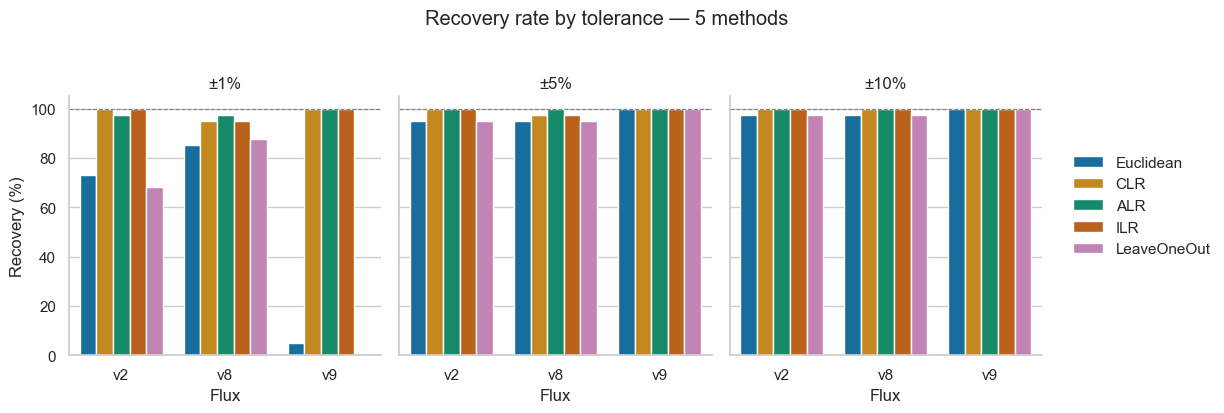

In [17]:
tolerances = [0.01, 0.05, 0.10]
recovery_rows = []
for v in flux_vars:
    for method in METHODS:
        sub = df_clean[(df_clean["Flux"] == v) & (df_clean["Method"] == method)]
        rel_err = (sub["Residual"] / sub["True"]).abs()
        for tol in tolerances:
            recovery_rows.append({
                "Flux": v, "Method": method,
                "Tolerance": f"\u00b1{int(tol*100)}%",
                "Recovery (%)": round(100 * (rel_err <= tol).mean(), 1),
            })

recovery_df = pd.DataFrame(recovery_rows)
print(recovery_df.pivot_table(
    index=["Flux", "Method"], columns="Tolerance", values="Recovery (%)"
).to_string())

g = sns.FacetGrid(recovery_df, col="Tolerance", height=4, aspect=0.9, sharey=True)
g.map_dataframe(
    sns.barplot, x="Flux", y="Recovery (%)", hue="Method",
    hue_order=METHODS, order=flux_vars,
    palette="colorblind", errorbar=None,
)
g.add_legend()
g.set_axis_labels("Flux", "Recovery (%)")
g.set_titles(col_template="{col_name}")
g.figure.suptitle("Recovery rate by tolerance \u2014 5 methods", y=1.03)
for ax in g.axes.flat:
    ax.set_ylim(0, 105)
    ax.axhline(100, color="grey", lw=0.8, ls="--")
g.tight_layout()
plt.savefig("../figures/alr_ilr_recovery.png", dpi=150, bbox_inches="tight")
plt.show()

## Transformed true MIDs across all LHS samples

Each column is a metabolite. Each row shows the MID after a different
transform: Original (simplex), CLR, ALR, ILR.

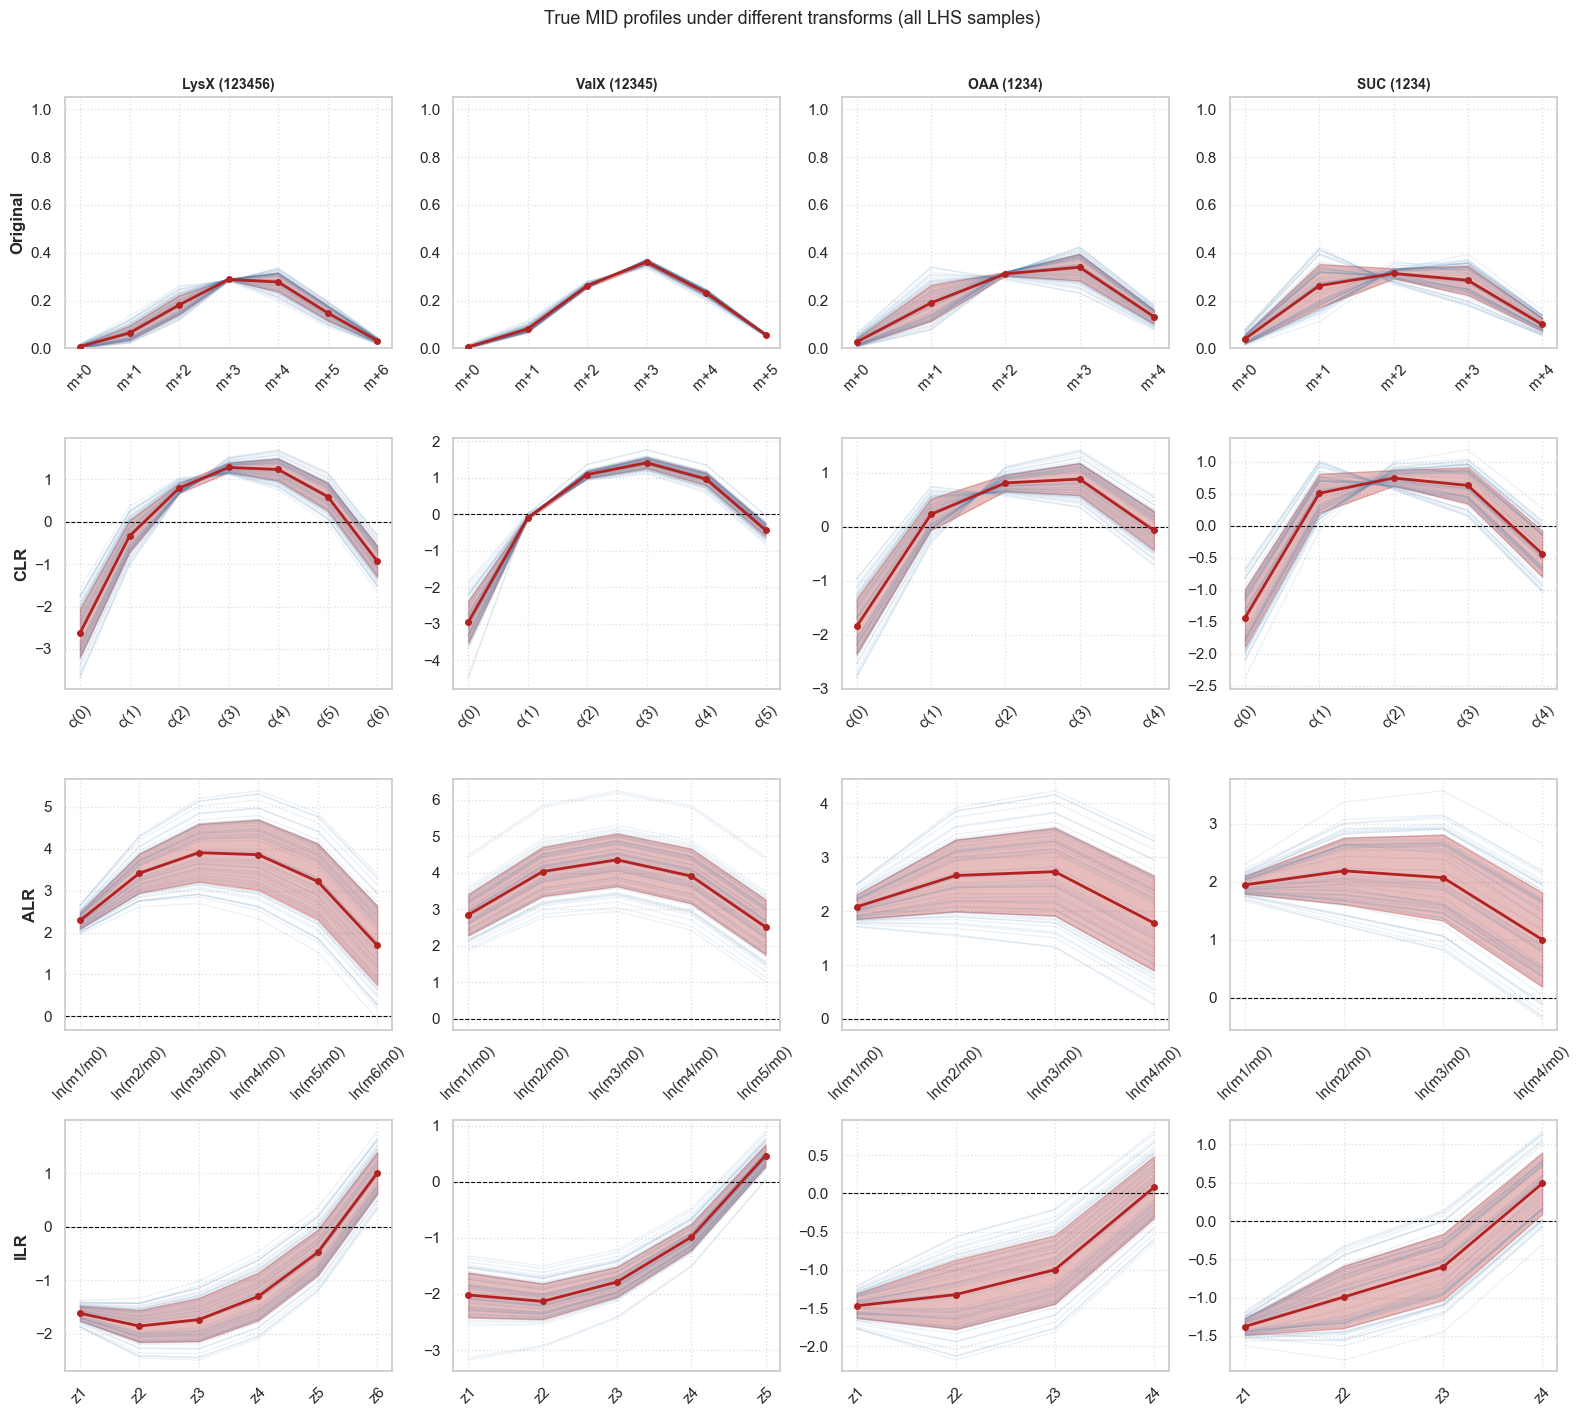

In [18]:
transform_fns = {
    "Original": lambda x: x,
    "CLR":      clr_func,
    "ALR":      alr_func,
    "ILR":      ilr_func,
}

met_keys   = list(batch_true_mids[0].keys())
met_labels = {
    "lysx_123456": "LysX (123456)",
    "valx_12345":  "ValX (12345)",
    "aspx_1234":   "OAA (1234)",
    "suc_1234":    "SUC (1234)",
}
t_names = list(transform_fns.keys())

# ... (Previous code remains the same) ...

sns.set_theme(style="whitegrid", palette="colorblind")
fig, axes = plt.subplots(
    len(t_names), len(met_keys),
    figsize=(4 * len(met_keys), 3.5 * len(t_names)),
    squeeze=False,
)
fig.suptitle("True MID profiles under different transforms (all LHS samples)",
             fontsize=13, y=1.01)

for row_idx, (tname, tfn) in enumerate(transform_fns.items()):
    for col_idx, met_key in enumerate(met_keys):
        ax = axes[row_idx, col_idx]

        # 1. Compute transformed values
        all_vals = []
        for mids in batch_true_mids:
            mid_jax = jnp.array(mids[met_key])
            # Handle potential JAX vs Numpy array issues
            val = np.array(tfn(mid_jax))
            all_vals.append(val)
        
        # Stack to shape (N_samples, N_components)
        arr = np.array(all_vals)
        n_comp = arr.shape[1]

        # 2. DEFINE DYNAMIC LABELS based on transformation
        if tname == "Original":
            x_labels = [f"m+{j}" for j in range(n_comp)]
            ax.set_ylim(0, 1.05) # Only bound 0-1 for original probability space
            
        elif tname == "CLR":
            # CLR preserves number of components
            x_labels = [f"c({j})" for j in range(n_comp)]
            
        elif tname == "ALR":
            # ALR drops one component (usually the last one is the denominator)
            # Label them as log-ratios relative to the reference
            x_labels = [f"ln(m{j+1}/m0)" for j in range(n_comp)]
            
        elif tname == "ILR":
            # ILR creates abstract coordinates
            x_labels = [f"z{j+1}" for j in range(n_comp)]

        # 3. PLOT
        # Spaghetti lines (subset to first 100 for speed/clarity if needed)
        for vals in all_vals[:100]: 
            ax.plot(x_labels, vals, color="steelblue", alpha=0.1, lw=1)

        # Mean + SD band
        mean_v = arr.mean(axis=0)
        std_v = arr.std(axis=0)
        
        ax.fill_between(
            range(n_comp), # Use range index for fill_between
            mean_v - std_v, mean_v + std_v,
            alpha=0.3, color="firebrick", label="Mean ± SD"
        )
        ax.plot(x_labels, mean_v,
                color="firebrick", lw=2, marker="o", ms=4, zorder=3)

        # 4. STYLING
        if row_idx == 0:
            ax.set_title(met_labels.get(met_key, met_key), fontsize=10, fontweight='bold')
        
        if col_idx == 0:
            ax.set_ylabel(tname, fontsize=12, fontweight="bold")
            
        # Add a zero line for log-ratio transforms (helps visualize centering)
        if tname != "Original":
            ax.axhline(0, color='black', linewidth=0.8, linestyle='--')

        ax.tick_params(axis="x", rotation=45)
        ax.grid(True, linestyle=':', alpha=0.6)

fig.tight_layout()
plt.savefig("../figures/alr_ilr_transformed_mids_corrected.png", dpi=150, bbox_inches="tight")
plt.show()